In [1]:
import os
print(os.getcwd())
print(os.listdir("data"))


C:\Users\AARUSHI\OneDrive\Desktop\AI project
['.ipynb_checkpoints', 'phishing_OG.csv.xlsx']


In [2]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

df = pd.read_excel("data/phishing_OG.csv.xlsx")
print(df.shape)
df.head()

(11054, 32)


,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,-1,1,-1,-1,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                11054 non-null  int64
 1   UsingIP              11054 non-null  int64
 2   LongURL              11054 non-null  int64
 3   ShortURL             11054 non-null  int64
 4   Symbol@              11054 non-null  int64
 5   Redirecting//        11054 non-null  int64
 6   PrefixSuffix-        11054 non-null  int64
 7   SubDomains           11054 non-null  int64
 8   HTTPS                11054 non-null  int64
 9   DomainRegLen         11054 non-null  int64
 10  Favicon              11054 non-null  int64
 11  NonStdPort           11054 non-null  int64
 12  HTTPSDomainURL       11054 non-null  int64
 13  RequestURL           11054 non-null  int64
 14  AnchorURL            11054 non-null  int64
 15  LinksInScriptTags    11054 non-null  int64
 16  ServerFormHandler    11054 non-nu

In [5]:
df.isnull().sum()


Index                  0
UsingIP                0
LongURL                0
ShortURL               0
Symbol@                0
Redirecting//          0
PrefixSuffix-          0
SubDomains             0
HTTPS                  0
DomainRegLen           0
Favicon                0
NonStdPort             0
HTTPSDomainURL         0
RequestURL             0
AnchorURL              0
LinksInScriptTags      0
ServerFormHandler      0
InfoEmail              0
AbnormalURL            0
WebsiteForwarding      0
StatusBarCust          0
DisableRightClick      0
UsingPopupWindow       0
IframeRedirection      0
AgeofDomain            0
DNSRecording           0
WebsiteTraffic         0
PageRank               0
GoogleIndex            0
LinksPointingToPage    0
StatsReport            0
class                  0
dtype: int64

In [6]:
print("Duplicates (all 32 columns):", df.duplicated().sum())
print("Duplicates (ignoring Index):", df.drop(columns="Index").duplicated().sum())

Duplicates (all 32 columns): 0
Duplicates (ignoring Index): 5205


In [7]:
print(df["class"].value_counts())
print()
print(df["class"].value_counts(normalize=True).round(3))

class
 1    6157
-1    4897
Name: count, dtype: int64

class
 1    0.557
-1    0.443
Name: proportion, dtype: float64


In [8]:
df_clean = df.drop(columns="Index")
print(df_clean.shape)

(11054, 31)


In [9]:
df_clean = df_clean.drop_duplicates()
print(df_clean.shape)
print("Duplicates left:", df_clean.duplicated().sum())

(5849, 31)
Duplicates left: 0


In [10]:
print(df_clean["class"].value_counts())
print()
print(df_clean["class"].value_counts(normalize=True).round(3))

class
-1    3019
 1    2830
Name: count, dtype: int64

class
-1    0.516
 1    0.484
Name: proportion, dtype: float64


In [11]:
df_clean.groupby("class")[["HTTPS", "AnchorURL", "UsingIP", "PrefixSuffix-"]].mean().round(2)

,HTTPS,AnchorURL,UsingIP,PrefixSuffix-
class,,,,
-1,-0.47,-0.62,0.03,-1.0
1,0.81,0.37,0.24,-0.5


In [12]:
X = df_clean.drop(columns="class")
y = df_clean["class"]

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (5849, 30)
y shape: (5849,)


,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,...,DisableRightClick,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport
0,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
1,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
2,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
3,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1
4,-1,0,-1,1,-1,-1,1,1,-1,1,...,1,1,1,1,1,1,-1,1,-1,-1


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (4679, 30)
X_test:  (1170, 30)
y_train: (4679,)
y_test:  (1170,)


In [14]:
print(y_train.value_counts(normalize=True).round(3))
print()
print(y_test.value_counts(normalize=True).round(3))

class
-1    0.516
 1    0.484
Name: proportion, dtype: float64

class
-1    0.516
 1    0.484
Name: proportion, dtype: float64


In [15]:
corr = X_train.corrwith(y_train).abs().sort_values(ascending=False)
print(corr.round(3))

HTTPS                  0.700
AnchorURL              0.681
PrefixSuffix-          0.381
SubDomains             0.293
WebsiteTraffic         0.280
ServerFormHandler      0.276
LinksInScriptTags      0.245
RequestURL             0.235
DomainRegLen           0.218
GoogleIndex            0.119
StatsReport            0.117
UsingIP                0.107
AbnormalURL            0.086
ShortURL               0.070
AgeofDomain            0.065
LinksPointingToPage    0.064
PageRank               0.049
LongURL                0.048
HTTPSDomainURL         0.045
DNSRecording           0.042
Symbol@                0.040
WebsiteForwarding      0.033
Redirecting//          0.028
NonStdPort             0.022
Favicon                0.018
DisableRightClick      0.018
StatusBarCust          0.016
UsingPopupWindow       0.015
IframeRedirection      0.007
InfoEmail              0.005
dtype: float64


In [16]:
#Training the Random forest:

In [17]:
corr = X_train.corrwith(y_train).abs().sort_values(ascending=False)
print(corr.round(3))

HTTPS                  0.700
AnchorURL              0.681
PrefixSuffix-          0.381
SubDomains             0.293
WebsiteTraffic         0.280
ServerFormHandler      0.276
LinksInScriptTags      0.245
RequestURL             0.235
DomainRegLen           0.218
GoogleIndex            0.119
StatsReport            0.117
UsingIP                0.107
AbnormalURL            0.086
ShortURL               0.070
AgeofDomain            0.065
LinksPointingToPage    0.064
PageRank               0.049
LongURL                0.048
HTTPSDomainURL         0.045
DNSRecording           0.042
Symbol@                0.040
WebsiteForwarding      0.033
Redirecting//          0.028
NonStdPort             0.022
Favicon                0.018
DisableRightClick      0.018
StatusBarCust          0.016
UsingPopupWindow       0.015
IframeRedirection      0.007
InfoEmail              0.005
dtype: float64


In [18]:
keep = corr.head(21).index
selected = [c for c in X_train.columns if c in keep]
dropped = [c for c in X_train.columns if c not in keep]

print("Kept (21):", selected)
print()
print("Dropped (9):", dropped)

X_train_sel = X_train[selected]
X_test_sel = X_test[selected]
print(X_train_sel.shape, X_test_sel.shape)

Kept (21): ['UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL', 'LinksInScriptTags', 'ServerFormHandler', 'AbnormalURL', 'AgeofDomain', 'DNSRecording', 'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage', 'StatsReport']

Dropped (9): ['Redirecting//', 'Favicon', 'NonStdPort', 'InfoEmail', 'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick', 'UsingPopupWindow', 'IframeRedirection']
(4679, 21) (1170, 21)


In [19]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_sel, y_train)
print("Model trained.")

Model trained.


In [20]:
y_pred = model.predict(X_test_sel)

print("Predicted:", y_pred[:10])
print("Actual:   ", y_test.values[:10])

Predicted: [-1 -1 -1 -1  1  1 -1  1  1 -1]
Actual:    [-1 -1 -1 -1  1  1 -1  1 -1 -1]


In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=-1)
rec  = recall_score(y_test, y_pred, pos_label=-1)
f1   = f1_score(y_test, y_pred, pos_label=-1)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}  (phishing = positive class)")
print(f"Recall   : {rec:.4f}  (phishing = positive class)")
print(f"F1-score : {f1:.4f}  (phishing = positive class)")

Accuracy : 0.9385
Precision: 0.9433  (phishing = positive class)
Recall   : 0.9371  (phishing = positive class)
F1-score : 0.9402  (phishing = positive class)


[[566  38]
 [ 34 532]]
TP=566  FN=38  FP=34  TN=532


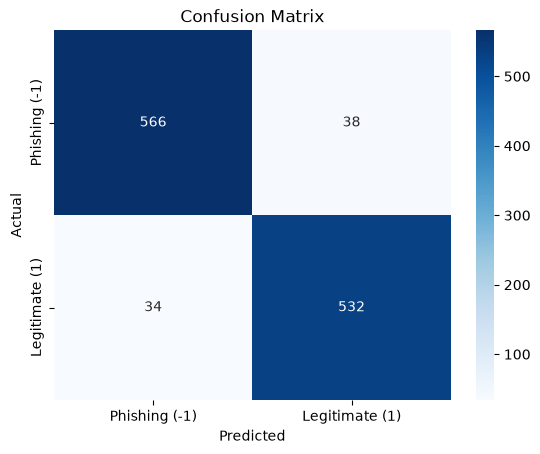

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])
tp, fn, fp, tn = cm.ravel()
print(cm)
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Phishing (-1)", "Legitimate (1)"],
            yticklabels=["Phishing (-1)", "Legitimate (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, labels=[-1, 1],
                            target_names=["Phishing", "Legitimate"]))

              precision    recall  f1-score   support

    Phishing       0.94      0.94      0.94       604
  Legitimate       0.93      0.94      0.94       566

    accuracy                           0.94      1170
   macro avg       0.94      0.94      0.94      1170
weighted avg       0.94      0.94      0.94      1170



In [24]:
train_acc = accuracy_score(y_train, model.predict(X_train_sel))
print(f"Training accuracy: {train_acc:.4f}")
print(f"Test accuracy    : {acc:.4f}")

Training accuracy: 0.9885
Test accuracy    : 0.9385


In [25]:
import pickle

with open("phishing_rf.pkl", "wb") as f:
    pickle.dump(model, f)

print("Saved: phishing_rf.pkl")
print("Features the model expects, in order:")
for i, name in enumerate(model.feature_names_in_, start=1):
    print(i, name)

Saved: phishing_rf.pkl
Features the model expects, in order:
1 UsingIP
2 LongURL
3 ShortURL
4 Symbol@
5 PrefixSuffix-
6 SubDomains
7 HTTPS
8 DomainRegLen
9 HTTPSDomainURL
10 RequestURL
11 AnchorURL
12 LinksInScriptTags
13 ServerFormHandler
14 AbnormalURL
15 AgeofDomain
16 DNSRecording
17 WebsiteTraffic
18 PageRank
19 GoogleIndex
20 LinksPointingToPage
21 StatsReport


In [26]:
with open("phishing_rf.pkl", "rb") as f:
    loaded = pickle.load(f)

same = (loaded.predict(X_test_sel) == y_pred).all()
print("Loaded model gives identical predictions:", same)

Loaded model gives identical predictions: True


In [27]:
import pandas as pd

importance = pd.Series(model.feature_importances_, index=model.feature_names_in_)
print(importance.sort_values(ascending=False).head(10).round(3))

HTTPS                  0.333
AnchorURL              0.234
SubDomains             0.063
PrefixSuffix-          0.061
WebsiteTraffic         0.055
LinksInScriptTags      0.045
ServerFormHandler      0.032
LinksPointingToPage    0.021
RequestURL             0.019
DomainRegLen           0.017
dtype: float64


In [28]:
import json

# 1. Which values does each feature take in the data? (for the dropdowns)
options = {c: sorted(int(v) for v in X_train_sel[c].unique()) for c in model.feature_names_in_}

# 2. One phishing and one legitimate test row the model classified correctly (demo examples)
correct = (y_pred == y_test.values)
phish_row = X_test_sel[correct & (y_test.values == -1)].iloc[0]
legit_row = X_test_sel[correct & (y_test.values == 1)].iloc[0]
examples = {
    "phishing":   {k: int(v) for k, v in phish_row.items()},
    "legitimate": {k: int(v) for k, v in legit_row.items()},
}

with open("feature_options.json", "w") as f:
    json.dump(options, f, indent=2)
with open("examples.json", "w") as f:
    json.dump(examples, f, indent=2)

for name, vals in options.items():
    print(f"{name:20s} {vals}")

UsingIP              [-1, 1]
LongURL              [-1, 0, 1]
ShortURL             [-1, 1]
Symbol@              [-1, 1]
PrefixSuffix-        [-1, 1]
SubDomains           [-1, 0, 1]
HTTPS                [-1, 0, 1]
DomainRegLen         [-1, 1]
HTTPSDomainURL       [-1, 1]
RequestURL           [-1, 1]
AnchorURL            [-1, 0, 1]
LinksInScriptTags    [-1, 0, 1]
ServerFormHandler    [-1, 0, 1]
AbnormalURL          [-1, 1]
AgeofDomain          [-1, 1]
DNSRecording         [-1, 1]
WebsiteTraffic       [-1, 0, 1]
PageRank             [-1, 1]
GoogleIndex          [-1, 1]
LinksPointingToPage  [-1, 0, 1]
StatsReport          [-1, 1]


In [29]:
%%writefile app.py
import json
import pickle

import pandas as pd
from flask import Flask, render_template, request

app = Flask(__name__)

# Load the trained model once, when the app starts
with open("phishing_rf.pkl", "rb") as f:
    model = pickle.load(f)

FEATURES = list(model.feature_names_in_)

with open("feature_options.json") as f:
    OPTIONS = json.load(f)
with open("examples.json") as f:
    EXAMPLES = json.load(f)


@app.route("/", methods=["GET", "POST"])
def home():
    values, result, phish_pct = {}, None, None

    if request.method == "POST":
        # 1. read the 21 form values and convert text -> whole numbers
        values = {name: int(request.form[name]) for name in FEATURES}
        # 2. one-row table, columns in the exact order the model was trained on
        row = pd.DataFrame([values], columns=FEATURES)
        # 3. ask the model
        prediction = model.predict(row)[0]
        result = "Phishing" if prediction == -1 else "Legitimate"
        # 4. roughly the share of the 100 trees that voted "phishing"
        phish_index = list(model.classes_).index(-1)
        phish_pct = round(model.predict_proba(row)[0][phish_index] * 100)
    else:
        # GET request: optionally pre-fill the form with a dataset example
        values = EXAMPLES.get(request.args.get("example"), {})

    return render_template("index.html", features=FEATURES, options=OPTIONS,
                           values=values, result=result, phish_pct=phish_pct)


if __name__ == "__main__":
    app.run(debug=True)

Overwriting app.py


In [30]:
%%writefile templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>URL Phishing Detection</title>
<style>
  body { font-family: "Segoe UI", Arial, sans-serif; background: #f3f5f9; margin: 0; color: #1f2937; }
  header { background: #1e3a8a; color: white; padding: 24px 16px; text-align: center; }
  header h1 { margin: 0 0 6px; font-size: 26px; }
  header p { margin: 0; opacity: .85; }
  main { max-width: 900px; margin: 24px auto; padding: 0 16px; }
  .card { background: white; border-radius: 10px; padding: 22px; box-shadow: 0 2px 8px rgba(0,0,0,.08); margin-bottom: 20px; }
  .grid { display: grid; grid-template-columns: repeat(auto-fill, minmax(190px, 1fr)); gap: 14px; }
  label { display: block; font-size: 13px; font-weight: 600; margin-bottom: 4px; }
  select { width: 100%; padding: 8px; border: 1px solid #cbd5e1; border-radius: 6px; font-size: 14px; }
  .actions { margin-top: 20px; display: flex; gap: 10px; flex-wrap: wrap; align-items: center; }
  button { background: #1e3a8a; color: white; border: 0; padding: 10px 24px; border-radius: 6px; font-size: 15px; cursor: pointer; }
  a.example { padding: 9px 14px; border: 1px solid #1e3a8a; color: #1e3a8a; border-radius: 6px; text-decoration: none; font-size: 14px; }
  .result { text-align: center; padding: 20px; border-radius: 10px; font-size: 24px; font-weight: 700; }
  .phishing { background: #fee2e2; color: #991b1b; }
  .legit { background: #dcfce7; color: #166534; }
  .note { font-size: 13px; color: #6b7280; text-align: center; margin: 10px 0 0; }
</style>
</head>
<body>
<header>
  <h1>URL-Based Phishing Detection</h1>
  <p>Random Forest classifier trained on website feature values</p>
</header>+
<main>

  {% if result %}
  <div class="card">
    <div class="result {{ 'phishing' if result == 'Phishing' else 'legit' }}">
      Prediction: {{ result }}
    </div>
    <p class="note">About {{ phish_pct }}% of the 100 trees voted "phishing" for these values.</p>
  </div>
  {% endif %}

  <div class="card">
    <form method="POST" action="/">
      <div class="grid">
        {% for name in features %}
        <div>
          <label for="{{ name }}">{{ name }}</label>
          <select id="{{ name }}" name="{{ name }}">
            {% for opt in options[name] %}
            <option value="{{ opt }}" {% if values.get(name) == opt %}selected{% endif %}>{{ opt }}</option>
            {% endfor %}
          </select>
        </div>
        {% endfor %}
      </div>
      <div class="actions">
        <button type="submit">Predict</button>
        <a class="example" href="/?example=legitimate">Load legitimate example</a>
        <a class="example" href="/?example=phishing">Load phishing example</a>
        <a class="example" href="/">Reset</a>
      </div>
    </form>
  </div>

  <p class="note">Educational project: the model takes the 21 website feature values from the dataset (-1, 0 or 1), not a raw URL.</p>
</main>
</body>
</html>

Overwriting templates/index.html
